# Solar Output Model Training
Step-by-step training for PS5. Run cells from top to bottom from the `notebooks` folder, with the four Kaggle CSVs in `../data/`.

The notebook shows the process and does not overwrite the deployed model unless you run the optional last cell.

## 1. Imports
pandas handles tables, NumPy handles maths, and scikit-learn provides the models and metrics.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
DATA = Path('../data')
PLANT = 2   # change to 1 for Plant 1
FEATURES = ['irradiation','module_temperature','ambient_temperature','hour_sin','hour_cos']

## 2. Load the data
Generation files have one row per inverter. Weather files have one row per time. Plant 1 uses day-first dates.

In [2]:
g = pd.read_csv(DATA/f'Plant_{PLANT}_Generation_Data.csv')
w = pd.read_csv(DATA/f'Plant_{PLANT}_Weather_Sensor_Data.csv')
g['t'] = pd.to_datetime(g.DATE_TIME, dayfirst=PLANT==1, format='mixed')
w['t'] = pd.to_datetime(w.DATE_TIME, format='mixed')
print(g.shape, w.shape, 'inverters:', g.SOURCE_KEY.nunique())
g.head()

(67698, 8) (3259, 7) inverters: 22


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,t
0,2020-05-15 00:00:00,4136001,4UPUqMRk7TRMgml,0.0,0.0,9425.000000,2.429011e+06,2020-05-15
1,2020-05-15 00:00:00,4136001,81aHJ1q11NBPMrL,0.0,0.0,0.000000,1.215279e+09,2020-05-15
2,2020-05-15 00:00:00,4136001,9kRcWv60rDACzjR,0.0,0.0,3075.333333,2.247720e+09,2020-05-15
3,2020-05-15 00:00:00,4136001,Et9kgGMDl729KT4,0.0,0.0,269.933333,1.704250e+06,2020-05-15
4,2020-05-15 00:00:00,4136001,IQ2d7wF4YD8zU1Q,0.0,0.0,3177.000000,1.994153e+07,2020-05-15


## EDA: Exploratory Data Analysis
Before choosing features or models, we look at the raw data: its size, quality, ranges and patterns. These cells only look at data and do not change it.

### E1. Shape, types and time span

In [3]:
for name, df in [('generation', g), ('weather', w)]:
    print(name, df.shape, '|', df.t.min(), 'to', df.t.max(), '|', df.t.dt.date.nunique(), 'days')
g.dtypes

generation (67698, 8) | 2020-05-15 00:00:00 to 2020-06-17 23:45:00 | 34 days
weather (3259, 7) | 2020-05-15 00:00:00 to 2020-06-17 23:45:00 | 34 days


DATE_TIME                 str
PLANT_ID                int64
SOURCE_KEY                str
DC_POWER              float64
AC_POWER              float64
DAILY_YIELD           float64
TOTAL_YIELD           float64
t              datetime64[us]
dtype: object

### E2. Missing readings
Each inverter should report every 15 minutes. Missing rows are gaps, not zero output.

generation rows 67698 of 71698 (94.4% complete)
weather timestamps 3259
null values:
none


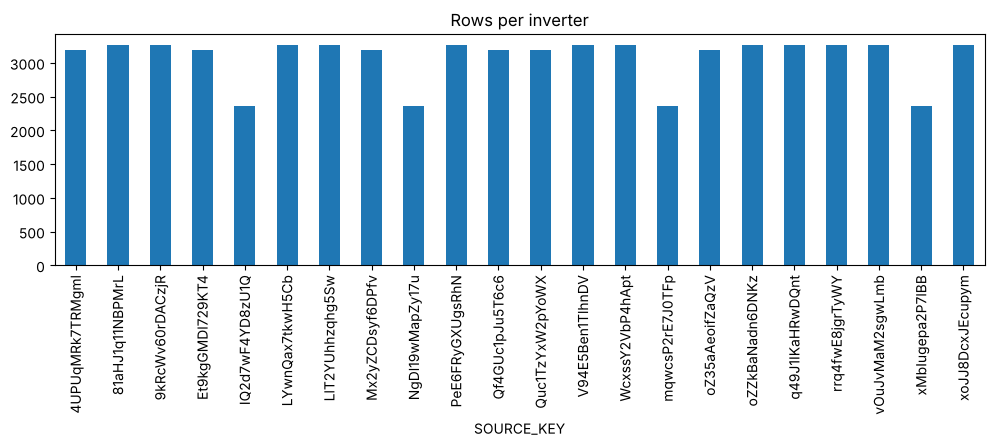

In [4]:
expected = g.t.nunique() * g.SOURCE_KEY.nunique()
print('generation rows', len(g), 'of', expected, f'({len(g)/expected:.1%} complete)')
print('weather timestamps', w.t.nunique())
print('null values:'); print(pd.concat([g.isna().sum(), w.isna().sum()]).loc[lambda s: s > 0] if (g.isna().sum().sum()+w.isna().sum().sum()) else 'none')
g.groupby('SOURCE_KEY').size().plot.bar(figsize=(12,3), title='Rows per inverter'); plt.show()

### E3. Summary statistics

In [5]:
g[['DC_POWER','AC_POWER','DAILY_YIELD','TOTAL_YIELD']].describe().round(1)

,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
count,67698.0,67698.0,67698.0,6.769800e+04
mean,246.7,241.3,3294.9,6.589448e+08
std,370.6,362.1,2919.4,7.296678e+08
min,0.0,0.0,0.0,0.000000e+00
25%,0.0,0.0,272.7,1.996494e+07
50%,0.0,0.0,2911.0,2.826276e+08
75%,446.6,438.2,5534.0,1.348495e+09
max,1420.9,1385.4,9873.0,2.247916e+09


In [6]:
w[['IRRADIATION','AMBIENT_TEMPERATURE','MODULE_TEMPERATURE']].describe().round(2)

,IRRADIATION,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE
count,3259.00,3259.00,3259.00
mean,0.23,28.07,32.77
std,0.31,4.06,11.34
min,0.00,20.94,20.27
25%,0.00,24.60,23.72
50%,0.02,26.98,27.53
75%,0.44,31.06,40.48
max,1.10,39.18,66.64


### E4. DC versus AC
An inverter converts DC to AC, so AC should be slightly below DC. A ratio far from about 0.97 suggests a unit or recording difference. Plant 1 shows about 0.1, a known oddity of this dataset, which is one reason our model uses AC only.

AC/DC ratio: 0.978


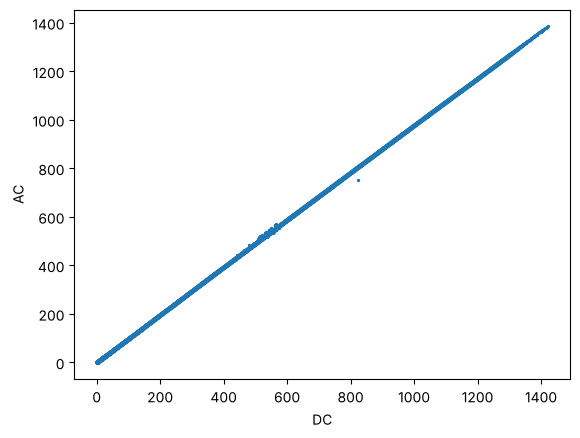

In [7]:
day_rows = g[g.DC_POWER > 0]
print('AC/DC ratio:', round(day_rows.AC_POWER.sum() / day_rows.DC_POWER.sum(), 3))
plt.scatter(day_rows.DC_POWER, day_rows.AC_POWER, s=2); plt.xlabel('DC'); plt.ylabel('AC'); plt.show()

### E5. Daily pattern
Output and sunlight should rise and fall together over the day.

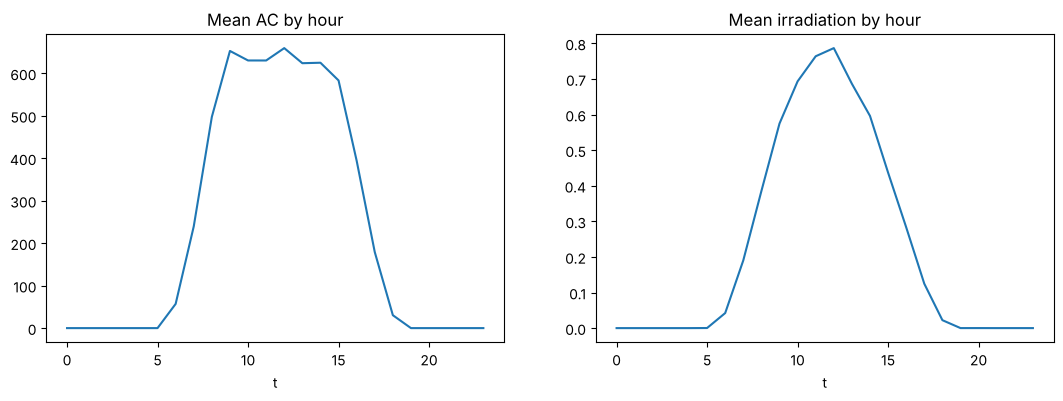

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13,4))
g.groupby(g.t.dt.hour).AC_POWER.mean().plot(ax=ax[0], title='Mean AC by hour')
w.groupby(w.t.dt.hour).IRRADIATION.mean().plot(ax=ax[1], title='Mean irradiation by hour'); plt.show()

### E6. Output against sunlight
The strongest single relationship. Points near zero at high sunlight are stops, not normal behaviour.

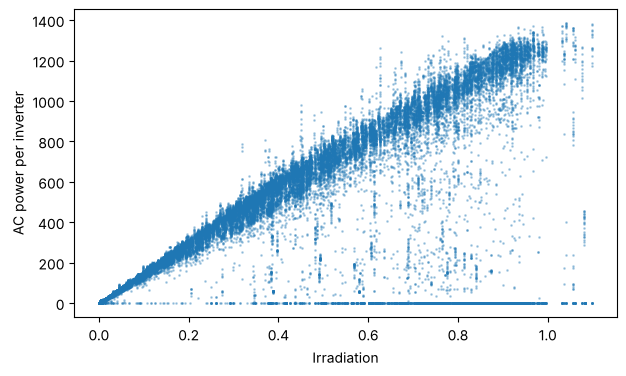

In [9]:
m = g.merge(w[['t','IRRADIATION','MODULE_TEMPERATURE','AMBIENT_TEMPERATURE']], on='t')
plt.figure(figsize=(7,4)); plt.scatter(m.IRRADIATION, m.AC_POWER, s=1, alpha=.3)
plt.xlabel('Irradiation'); plt.ylabel('AC power per inverter'); plt.show()

### E7. Temperatures
Panels heat above air temperature in sunlight. This is why module temperature is useful.

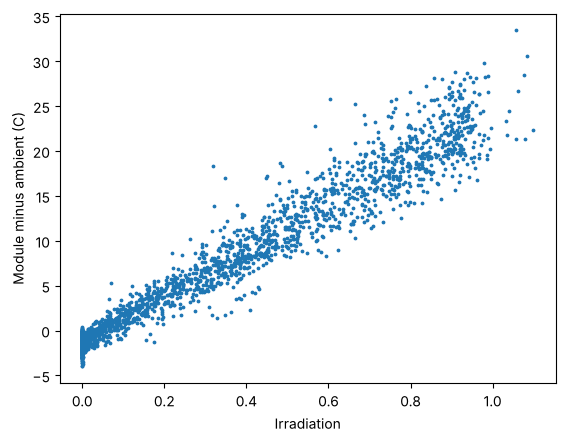

In [10]:
plt.scatter(w.IRRADIATION, w.MODULE_TEMPERATURE - w.AMBIENT_TEMPERATURE, s=3)
plt.xlabel('Irradiation'); plt.ylabel('Module minus ambient (C)'); plt.show()

### E8. Correlations
Values near 1 move together. Note that correlation only measures straight-line relationships.

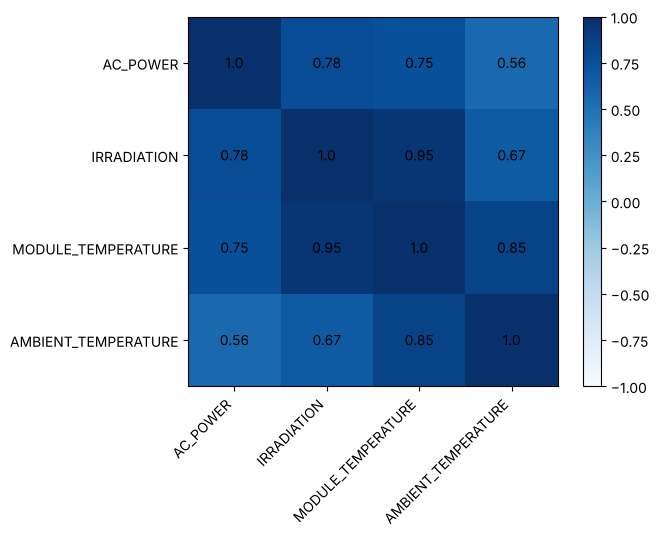

In [11]:
cols = ['AC_POWER','IRRADIATION','MODULE_TEMPERATURE','AMBIENT_TEMPERATURE']
cm = m[cols].corr().round(2)
plt.imshow(cm, cmap='Blues', vmin=-1, vmax=1); plt.xticks(range(4), cols, rotation=45, ha='right'); plt.yticks(range(4), cols)
for i in range(4):
    for j in range(4): plt.text(j, i, cm.iloc[i,j], ha='center', va='center')
plt.colorbar(); plt.show()

### E9. Daily totals
Shows good and poor days across the 34-day period.

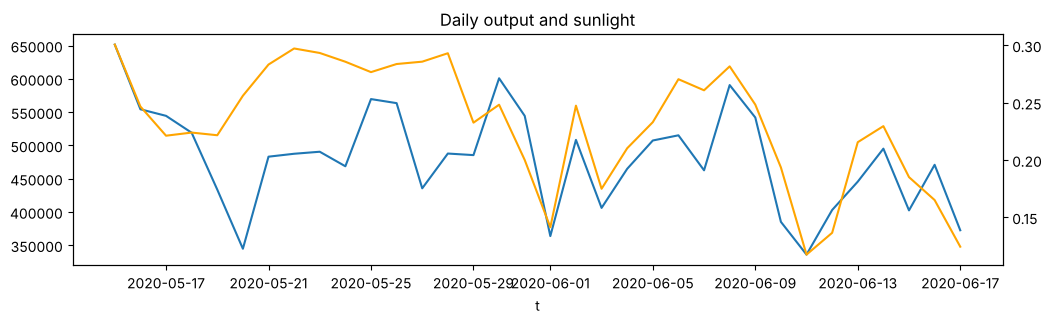

In [12]:
daily = m.groupby(m.t.dt.date).agg(ac=('AC_POWER','sum'), irr=('IRRADIATION','mean'))
ax = daily.ac.plot(figsize=(12,3), label='Total AC'); ax2 = ax.twinx(); daily.irr.plot(ax=ax2, color='orange', label='Mean irradiation')
ax.set_title('Daily output and sunlight'); plt.show()

### E10. Zero output in daylight
An inverter showing zero while the sun is strong is a recorded stop. This shaped our target design: we use running inverters so the model does not learn stops as normal.

Zero AC in sunlight: 17.0% of inverter readings


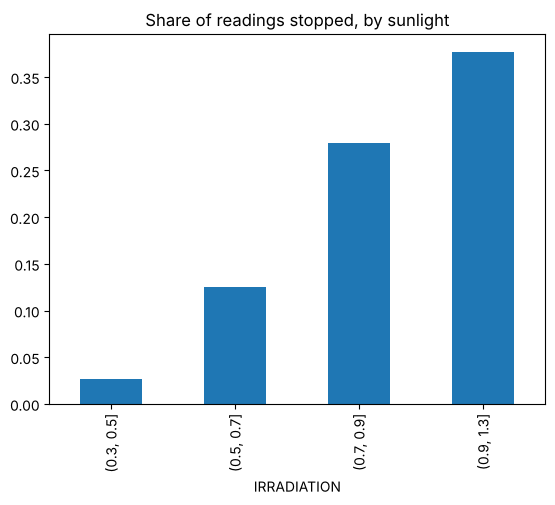

In [13]:
sunny = m[m.IRRADIATION > 0.3]
print(f'Zero AC in sunlight: {(sunny.AC_POWER == 0).mean():.1%} of inverter readings')
sunny.assign(stop=sunny.AC_POWER == 0).groupby(pd.cut(sunny.IRRADIATION, [.3,.5,.7,.9,1.3])).stop.mean().plot.bar(title='Share of readings stopped, by sunlight'); plt.show()

### E11. What EDA tells us
- Sunlight drives output most strongly, so irradiation is the main feature.
- Module temperature adds information because panels heat in sunlight.
- Output follows a clear daily cycle, so time of day is encoded as sine and cosine.
- AC is used as the target, given the DC unit oddity.
- Missing rows stay missing and are never treated as zero.
- Daylight stops are common at Plant 2, so the target uses running inverters.

Run this section once with `PLANT = 1` and once with `PLANT = 2` to compare.

## 3. Build the target
We want output **if inverters are running**. So we use the median running inverter multiplied by the inverter count. This stops recorded stops from teaching the model that strong sun means low output.

In [14]:
n_inv = g.SOURCE_KEY.nunique()
running = g[g.AC_POWER > 0].groupby('t').AC_POWER.median() * n_inv
w2 = w.drop_duplicates('t').set_index('t').sort_index()
d = pd.DataFrame({'irradiation': w2.IRRADIATION, 'module_temperature': w2.MODULE_TEMPERATURE,
                  'ambient_temperature': w2.AMBIENT_TEMPERATURE}).join(running.rename('y'))
d.loc[d.irradiation <= 0.02, 'y'] = d.y.where(d.irradiation > 0.02).fillna(0)  # dark means zero
d = d[d.y.notna() & d[FEATURES[:3]].notna().all(axis=1)]                        # missing is not zero
d.describe().round(2)

,irradiation,module_temperature,ambient_temperature,y
count,3250.00,3250.00,3250.00,3250.00
mean,0.23,32.73,28.06,6783.72
std,0.31,11.33,4.06,9061.82
min,0.00,20.27,20.94,0.00
25%,0.00,23.71,24.60,0.00
50%,0.02,27.49,26.95,0.00
75%,0.44,40.39,31.04,13153.76
max,1.10,66.64,39.18,29987.03


## 4. Create time features
Sine and cosine place the hour on a circle, so 23:00 and 00:00 are close.

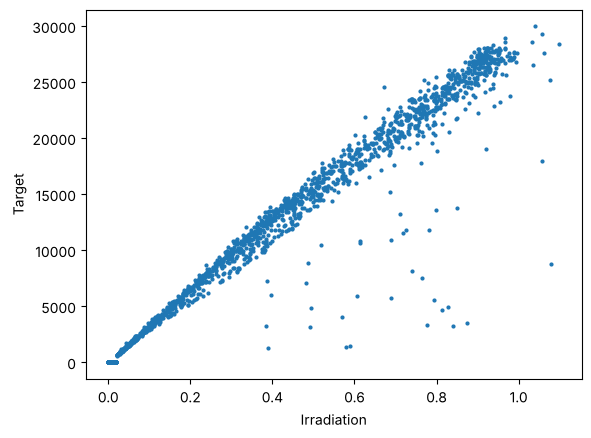

In [15]:
h = d.index.hour + d.index.minute/60
d['hour_sin'] = np.sin(2*np.pi*h/24)
d['hour_cos'] = np.cos(2*np.pi*h/24)
plt.scatter(d.irradiation, d.y, s=4); plt.xlabel('Irradiation'); plt.ylabel('Target'); plt.show()

## 5. Split by date
60% train, 20% calibration, 20% test. We split by time so the model is judged on future periods.

In [16]:
days = sorted(set(d.index.date))
a, b = days[int(len(days)*.6)], days[int(len(days)*.8)]
dt = pd.Series(d.index.date, index=d.index)
train, cal, test = d[dt < a], d[(dt >= a) & (dt < b)], d[dt >= b]
print(len(train), len(cal), len(test), 'test starts', b)

1912 669 669 test starts 2020-06-11


## 6. Define the candidates
We compare the three PS models with a few settings.

In [17]:
candidates = [('linear', {}, LinearRegression())]
for leaf in (3, 10):
    candidates.append(('random_forest', {'min_samples_leaf': leaf}, RandomForestRegressor(150, min_samples_leaf=leaf, random_state=0, n_jobs=-1)))
for c in (500, 2000, 8000):
    candidates.append(('svr', {'C': c}, make_pipeline(StandardScaler(), SVR(C=c, epsilon=20))))
def scores(y, p):
    y = np.asarray(y)
    return {'MAE': mean_absolute_error(y, p), 'RMSE': mean_squared_error(y, p)**.5, 'R2': r2_score(y, p),
            'Daylight MAE': mean_absolute_error(y[y > 0], p[y > 0])}

## 7. Train and choose using calibration only
The test set is not used to choose. Output is clipped at zero because negative power makes no sense here.

In [18]:
runs = []
for family, params, model in candidates:
    model.fit(train[FEATURES], train.y)
    p = model.predict(cal[FEATURES]).clip(0)
    runs.append({'family': family, 'params': params, 'calibration_mae': mean_absolute_error(cal.y, p), 'model': model})
runs_df = pd.DataFrame(runs).drop(columns='model').sort_values('calibration_mae')
best_by_family = {}
for r in sorted(runs, key=lambda x: x['calibration_mae']):
    best_by_family.setdefault(r['family'], r)
chosen = min(best_by_family, key=lambda k: best_by_family[k]['calibration_mae'])
print('Chosen:', chosen); runs_df.round(2)

Chosen: svr


,family,params,calibration_mae
5,svr,{'C': 8000},504.17
4,svr,{'C': 2000},514.07
2,random_forest,{'min_samples_leaf': 10},557.69
1,random_forest,{'min_samples_leaf': 3},584.12
3,svr,{'C': 500},600.60
0,linear,{},624.60


## 8. Final test scores
Also compare with a simple hour-of-day baseline.

In [19]:
table = {k: scores(test.y, v['model'].predict(test[FEATURES]).clip(0)) for k, v in best_by_family.items()}
base = test.assign(h=test.index.hour).h.map(train.assign(h=train.index.hour).groupby('h').y.mean()).fillna(0)
table['hour baseline'] = scores(test.y, base.values)
pd.DataFrame(table).T.round(4)

,MAE,RMSE,R2,Daylight MAE
svr,351.1257,1555.2392,0.9468,671.7027
random_forest,460.9719,1473.3392,0.9522,915.1044
linear,572.1619,1551.9136,0.9470,1089.4437
hour baseline,2591.8338,4761.8919,0.5010,5085.2899


## 9. Look at actual target versus prediction

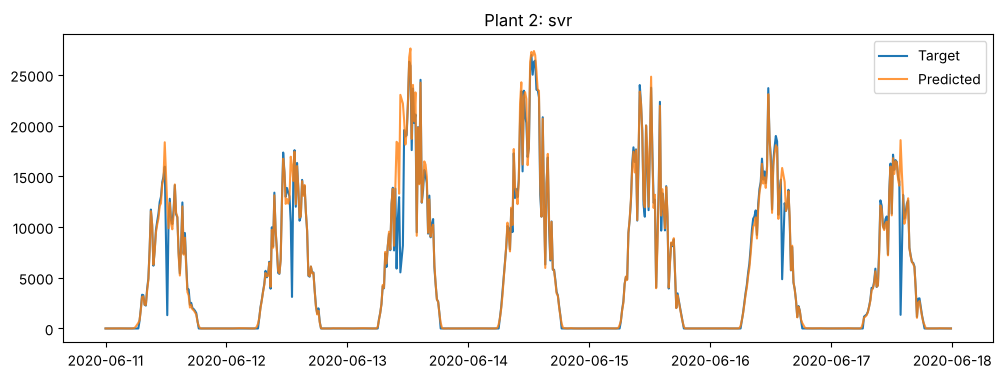

In [20]:
m = best_by_family[chosen]['model']; p = m.predict(test[FEATURES]).clip(0)
plt.figure(figsize=(12,4)); plt.plot(test.index, test.y, label='Target'); plt.plot(test.index, p, label='Predicted', alpha=.8)
plt.legend(); plt.title(f'Plant {PLANT}: {chosen}'); plt.show()

## 10. Same as deployed training
`ml/train.py` does these same steps for both plants and writes the model, metrics, tests and fingerprint. To replace the deployed model, run it from the project root, run tests, then commit. Do not retrain just to view results.